# Chapter 5 · The law of large numbers and the CLT

*Book 3 · Probability · Shelf I*

**Builds on:** [Chapter 2](02-random-variables.ipynb) (expectation and variance) and
[Chapter 3](03-the-common-distributions.ipynb) (the normal distribution).
**You will:** watch a sample mean settle, see a skewed variable's averages turn normal, and read off
how the error of an average shrinks with the sample size -- the rule that sizes every survey and
every simulation.

The **law of large numbers**: the average of $n$ independent draws converges to the expected value.
The **central limit theorem**: the error of that average is approximately normal, with standard
deviation $\sigma / \sqrt n$ -- whatever the distribution of the single draw, as long as its variance
is finite.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

from ds_toolbox import viz

viz.use_style()
rng = np.random.default_rng(5)

## The running mean settles

Exponential waits with mean 30 hours (heavily skewed). Five independent runs of the running mean:

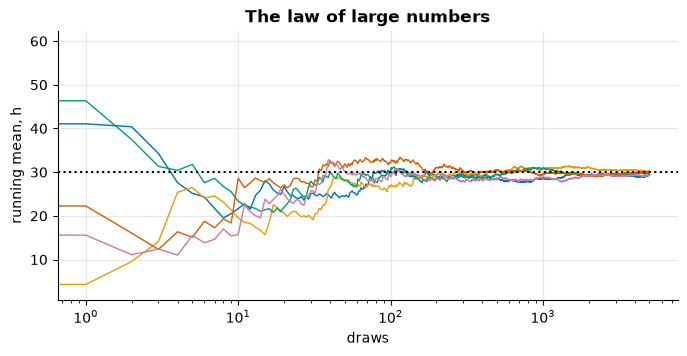

In [2]:
n = 5000
fig, ax = plt.subplots(figsize=(8, 3.5))
for _ in range(5):
    x = rng.exponential(30, n)
    ax.plot(np.cumsum(x) / np.arange(1, n + 1), lw=1)
ax.axhline(30, color="black", ls=":")
ax.set(xscale="log", xlabel="draws", ylabel="running mean, h", title="The law of large numbers");

## Averages become normal

Means of $n$ exponential draws, 20 000 times each. One draw is far from normal; the mean of 30 is
already close.

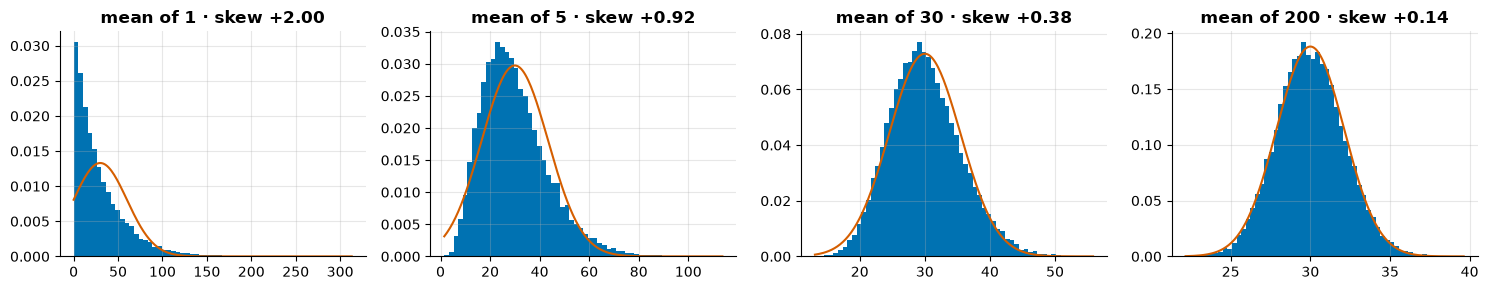

In [3]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3))
for ax, k in zip(axes, [1, 5, 30, 200], strict=True):
    means = rng.exponential(30, size=(20000, k)).mean(axis=1)
    ax.hist(means, bins=60, density=True, color=viz.PALETTE[0])
    grid = np.linspace(means.min(), means.max(), 200)
    ax.plot(grid, stats.norm(30, 30 / np.sqrt(k)).pdf(grid), color=viz.PALETTE[3])
    ax.set_title(f"mean of {k} · skew {stats.skew(means):+.2f}")
fig.tight_layout()

## Error shrinks with the square root

The standard error is $\sigma/\sqrt n$: four times the data halves the error. Measured, not assumed:

In [4]:
for k in (25, 100, 400, 1600):
    means = rng.exponential(30, size=(4000, k)).mean(axis=1)
    print(f"n = {k:5d}: spread of the mean {means.std():5.2f} h · sigma/sqrt(n) = {30 / np.sqrt(k):5.2f} h")

n =    25: spread of the mean  5.89 h · sigma/sqrt(n) =  6.00 h
n =   100: spread of the mean  2.97 h · sigma/sqrt(n) =  3.00 h
n =   400: spread of the mean  1.53 h · sigma/sqrt(n) =  1.50 h
n =  1600: spread of the mean  0.74 h · sigma/sqrt(n) =  0.75 h


## The cost of a rare event

The same rule sizes a simulation of a rare event. To estimate a probability $p$ from $N$ trials
with a relative error of 10 %, the standard error $\sqrt{p(1-p)/N}$ must be $0.1\,p$ -- so
$N \approx 100/p$. For a breach once in 60 years, $p \approx 0.016$ per simulated year and
$N \approx 6\,000$ years; for a car hit at $10^{-4}$, a million years. The challenge's simulations
are as long as they are because of this line.

In [5]:
for p in (0.1, 0.016, 1e-4):
    print(f"p = {p:g}: about {100 / p:,.0f} trials for 10 % relative error")

p = 0.1: about 1,000 trials for 10 % relative error
p = 0.016: about 6,250 trials for 10 % relative error
p = 0.0001: about 1,000,000 trials for 10 % relative error


## When the CLT fails

The theorem needs a finite variance. A Pareto distribution with tail index 1.5 has a mean but no
variance; its averages keep jumping when a giant draw arrives, and their spread does not fall as
$1/\sqrt n$.

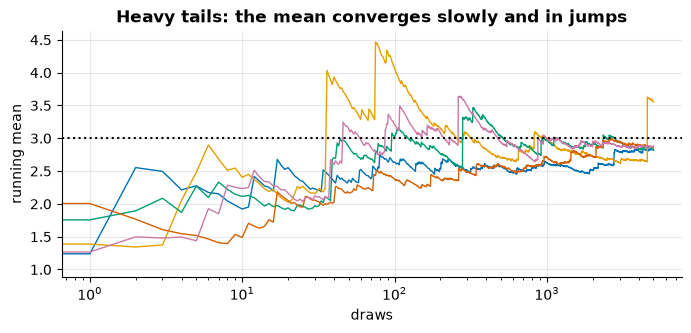

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.2))
for _ in range(5):
    x = stats.pareto(1.5).rvs(size=n, random_state=rng)
    ax.plot(np.cumsum(x) / np.arange(1, n + 1), lw=1)
ax.axhline(stats.pareto(1.5).mean(), color="black", ls=":")
ax.set(xscale="log", xlabel="draws", ylabel="running mean",
       title="Heavy tails: the mean converges slowly and in jumps");

## What to remember

- Averages converge to the expected value; their error is about $\sigma/\sqrt n$ and normal.
- Four times the data halves the error. A rare event needs about $100/p$ trials for 10 % precision.
- Heavy tails break the comfort: check the variance exists before trusting $\sigma/\sqrt n$.

## Exercises

1. Build a 95 % confidence interval for the mean gap from 50 exponential draws. How often does it
   contain 30 over 2 000 repetitions?
2. For a Pareto with tail index 2.5, does the spread of the mean fall like $1/\sqrt n$?
3. How many simulated years does a 5 % relative error on $p = 0.016$ need?

**Next:** [Chapter 6 · Monte Carlo](06-monte-carlo.ipynb)